# Testing the trained DINO ViT-Tiny

This notebook loads the **teacher backbone** from a DINO checkpoint and tests it on STL-10 **test** images in three ways:

1. **Attention maps** — CLS-token attention (the signature DINO result: emergent object segmentation).
2. **Linear-probe predictions** — a linear classifier on frozen features, showing per-image class predictions + accuracy.
3. **Feature similarity / k-NN** — nearest-neighbor retrieval by cosine similarity.

> The DINO model is a *feature extractor* — it has no built-in classifier, so the linear probe is trained here on the labeled STL-10 train split.

## 0. Setup

In [1]:
import os, sys

# Make the notebook runnable from either the project root or the test/ folder,
# and let it import the `src` package.
ROOT = os.getcwd()
if not os.path.isdir(os.path.join(ROOT, "src")):
    ROOT = os.path.dirname(ROOT)          # we're inside test/, step up
assert os.path.isdir(os.path.join(ROOT, "src")), f"Could not locate project root from {os.getcwd()}"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("Project root:", ROOT)

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import transforms
from torchvision.datasets import STL10

from src.vision_transformer import VisionTransformer

torch.manual_seed(0)
DEVICE = "cpu"

# ---- config ----
CKPT = os.path.join(ROOT, "outputs", "checkpoints", "dino_epoch20.pt")   # final checkpoint
DATA = os.path.join(ROOT, "data")

# STL-10 normalization stats (must match training / evaluate.py)
MEAN = (0.4467, 0.4398, 0.4066)
STD  = (0.2603, 0.2566, 0.2713)
CLASSES = ["airplane", "bird", "car", "cat", "deer",
           "dog", "horse", "monkey", "ship", "truck"]
print("Checkpoint:", CKPT, "| exists:", os.path.isfile(CKPT))

Project root: d:\projects\DINO
Checkpoint: d:\projects\DINO\outputs\checkpoints\dino_epoch20.pt | exists: True


## 1. Load the trained backbone

We load the **teacher** weights (they give slightly cleaner features than the student), stripping the `backbone.` prefix that the `MultiCropWrapper` added during training.

In [2]:
backbone = VisionTransformer().to(DEVICE)
state = torch.load(CKPT, map_location=DEVICE)
bb_state = {k.replace("backbone.", ""): v
            for k, v in state["teacher"].items()
            if k.startswith("backbone.")}
missing, unexpected = backbone.load_state_dict(bb_state, strict=False)
backbone.eval()
print(f"Loaded checkpoint from epoch {state.get('epoch', '?') } "
      f"| missing keys: {len(missing)} | unexpected: {len(unexpected)}")
n_params = sum(p.numel() for p in backbone.parameters())
print(f"Backbone params: {n_params/1e6:.2f}M")

Loaded checkpoint from epoch 19 | missing keys: 0 | unexpected: 0
Backbone params: 2.72M


In [3]:
# STL-10 test split, resized to the 64x64 the model was trained on.
tf = transforms.Compose([
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_ds = STL10(root=DATA, split="test", transform=tf, download=True)
print("Test images:", len(test_ds))

def unnormalize(img):
    """Undo Normalize for display."""
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (img * s + m).clamp(0, 1).permute(1, 2, 0)

Test images: 8000


## 2. Attention maps (emergent segmentation)

For each test image we take the last block's attention and look at what the **CLS token** attends to across the 8×8 patch grid, per head.

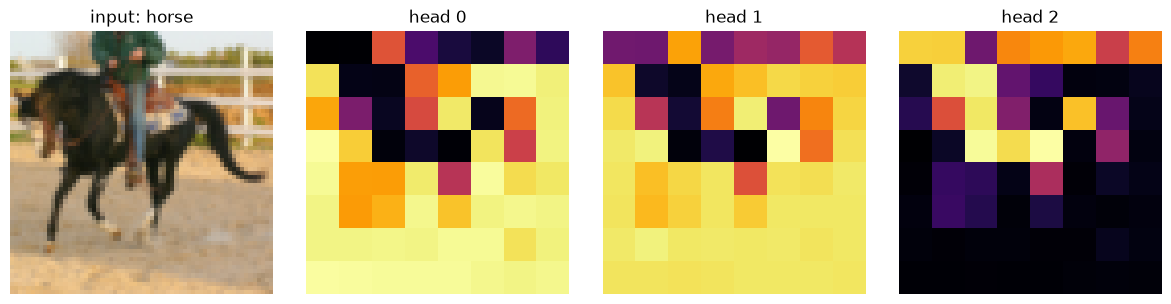

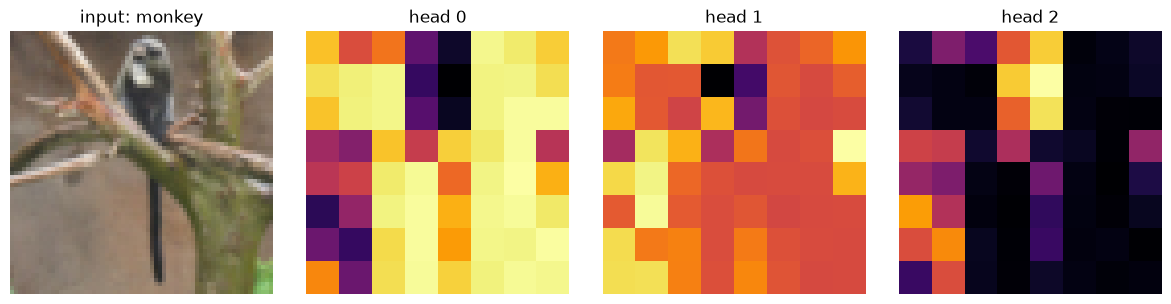

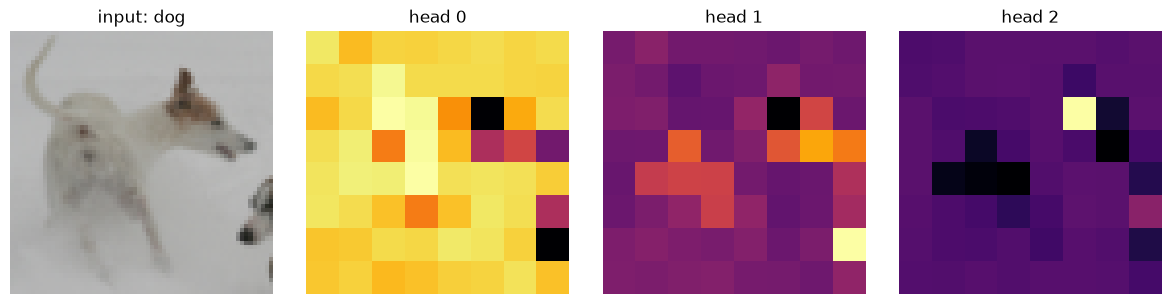

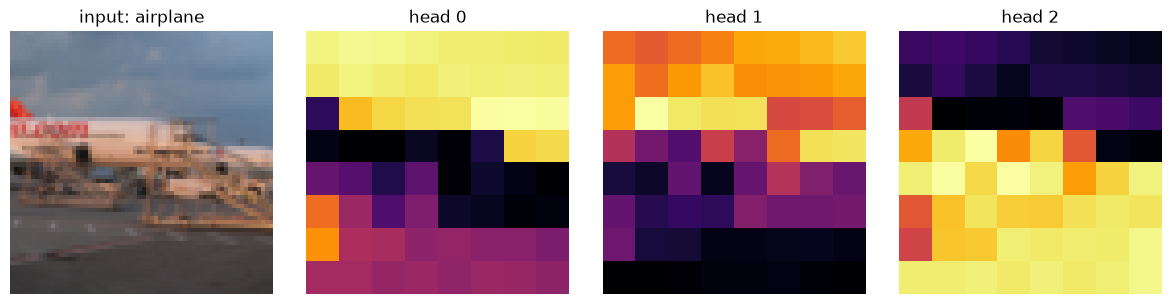

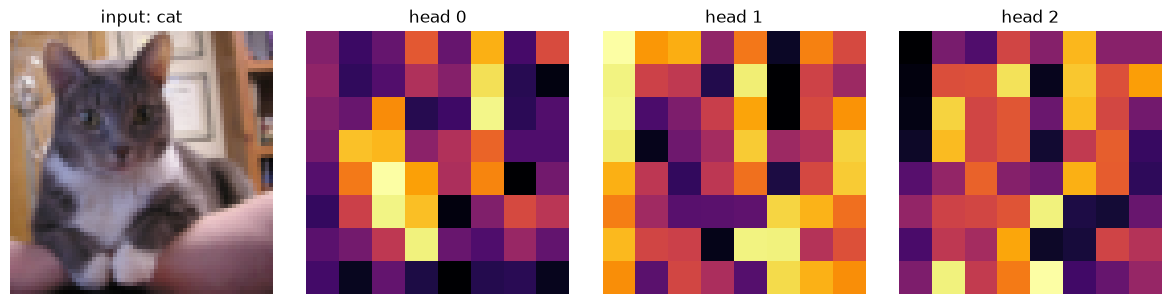

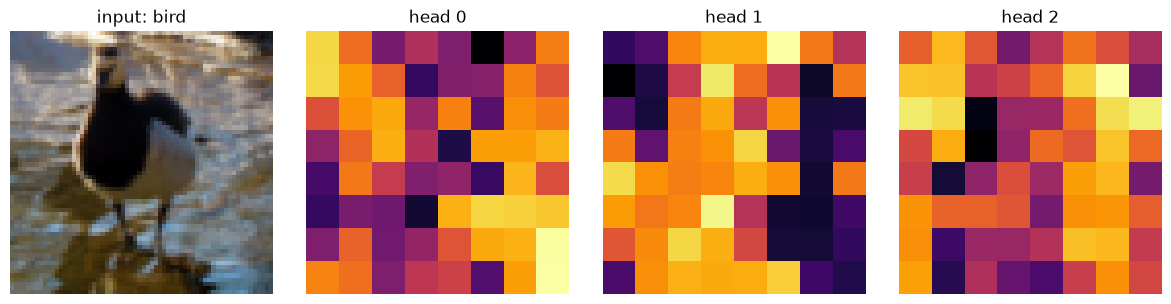

In [4]:
N_SHOW = 6   # how many test images to visualize

for i in range(N_SHOW):
    img, label = test_ds[i]
    with torch.no_grad():
        attn = backbone.get_last_attention(img.unsqueeze(0))   # (1, heads, N+1, N+1)
    cls_attn = attn[0, :, 0, 1:]              # CLS -> patches, per head: (heads, 64)
    n_heads = cls_attn.shape[0]
    maps = cls_attn.reshape(n_heads, 8, 8)

    fig, axes = plt.subplots(1, n_heads + 1, figsize=(3 * (n_heads + 1), 3))
    axes[0].imshow(unnormalize(img))
    axes[0].set_title(f"input: {CLASSES[label]}")
    axes[0].axis("off")
    for h in range(n_heads):
        axes[h + 1].imshow(maps[h], cmap="inferno")
        axes[h + 1].set_title(f"head {h}")
        axes[h + 1].axis("off")
    plt.tight_layout()
    plt.show()

## 3. Linear-probe predictions

Extract frozen features for the labeled STL-10 **train** and **test** splits, train a single linear layer on top, then show actual per-image predictions and overall accuracy. Mirrors [src/evaluate.py](../src/evaluate.py).

In [5]:
from torch.utils.data import DataLoader

def extract_features(ds, batch=64):
    loader = DataLoader(ds, batch_size=batch, shuffle=False)
    feats, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            feats.append(backbone(x))
            labels.append(y)
    return torch.cat(feats), torch.cat(labels)

train_ds = STL10(root=DATA, split="train", transform=tf, download=True)
print("Extracting train features...")
train_f, train_y = extract_features(train_ds)
print("Extracting test features...")
test_f, test_y = extract_features(test_ds)
print("train:", train_f.shape, "| test:", test_f.shape)

Extracting train features...
Extracting test features...
train: torch.Size([5000, 192]) | test: torch.Size([8000, 192])


In [6]:
# Train a linear classifier on frozen features.
clf = nn.Linear(192, 10)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for epoch in range(50):
    idx = torch.randperm(len(train_f))
    for i in range(0, len(idx), 256):
        b = idx[i:i + 256]
        loss = nn.functional.cross_entropy(clf(train_f[b]), train_y[b])
        opt.zero_grad(); loss.backward(); opt.step()

with torch.no_grad():
    logits = clf(test_f)
    preds = logits.argmax(1)
acc = (preds == test_y).float().mean().item()
print(f"Linear probe top-1 accuracy on {len(test_y)} test images: {acc:.4f}")

Linear probe top-1 accuracy on 8000 test images: 0.3686


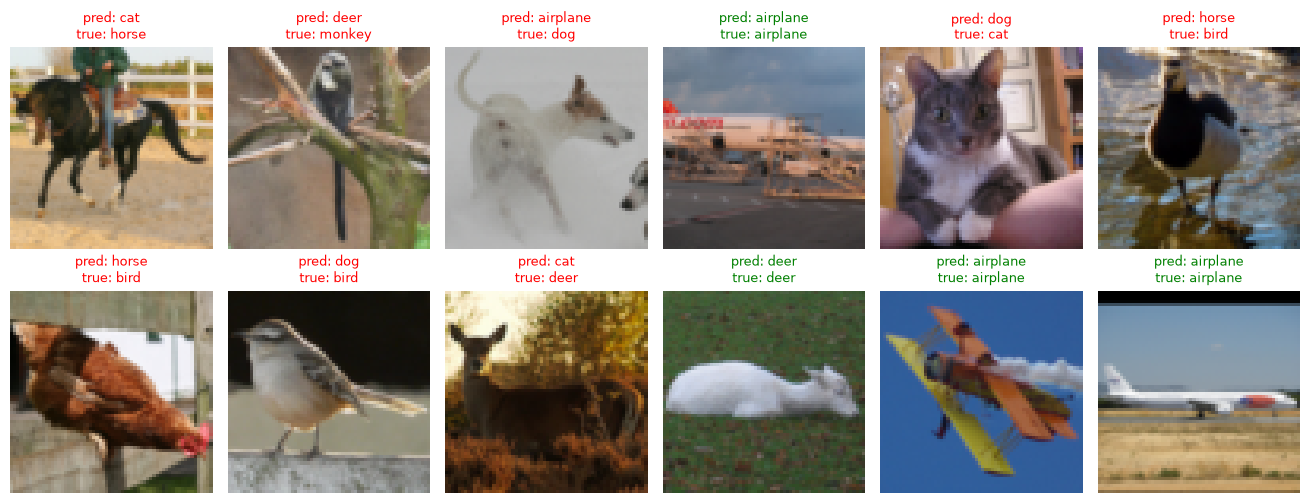

In [7]:
# Show predictions on individual test images (green = correct, red = wrong).
N_SHOW = 12
cols = 6
rows = (N_SHOW + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.6 * rows))
for i, ax in enumerate(axes.ravel()):
    if i >= N_SHOW:
        ax.axis("off"); continue
    img, label = test_ds[i]
    p = preds[i].item()
    ok = (p == label)
    ax.imshow(unnormalize(img))
    ax.set_title(f"pred: {CLASSES[p]}\ntrue: {CLASSES[label]}",
                 color=("green" if ok else "red"), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
# Per-class accuracy.
print(f"{'class':<10} {'acc':>6}   {'n':>4}")
for c in range(10):
    mask = (test_y == c)
    a = (preds[mask] == test_y[mask]).float().mean().item()
    print(f"{CLASSES[c]:<10} {a:>6.3f}   {int(mask.sum()):>4}")

class         acc      n
airplane    0.575    800
bird        0.117    800
car         0.553    800
cat         0.181    800
deer        0.493    800
dog         0.209    800
horse       0.308    800
monkey      0.346    800
ship        0.570    800
truck       0.335    800


## 4. Feature similarity / k-NN retrieval

Using the frozen features directly (no classifier): pick a query test image and find the most similar test images by **cosine similarity**. Good features cluster same-class images together.

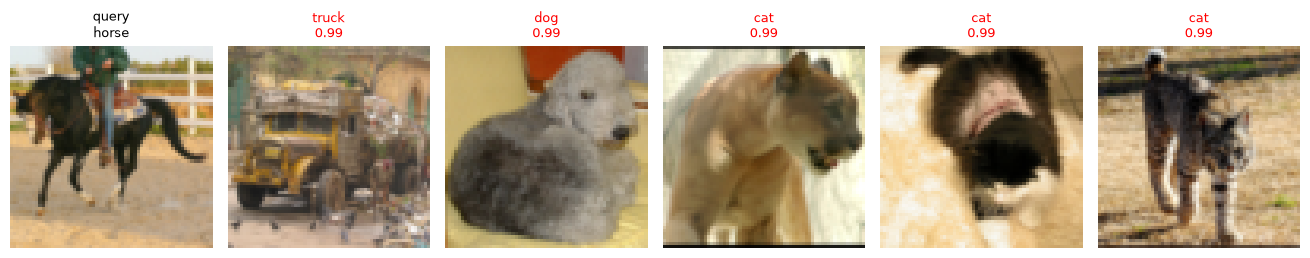

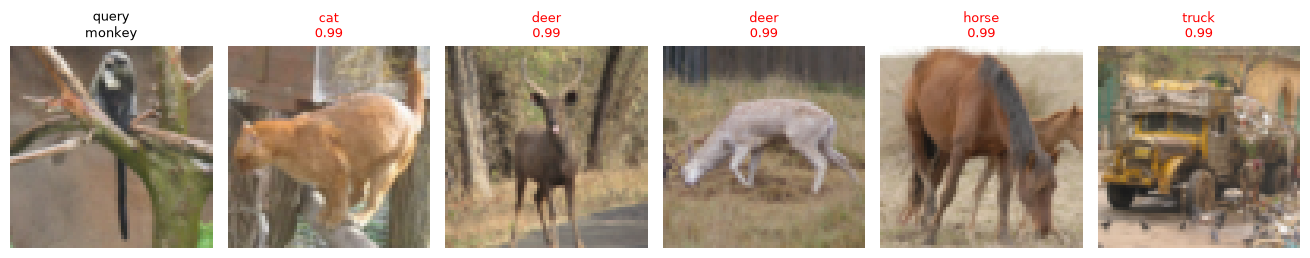

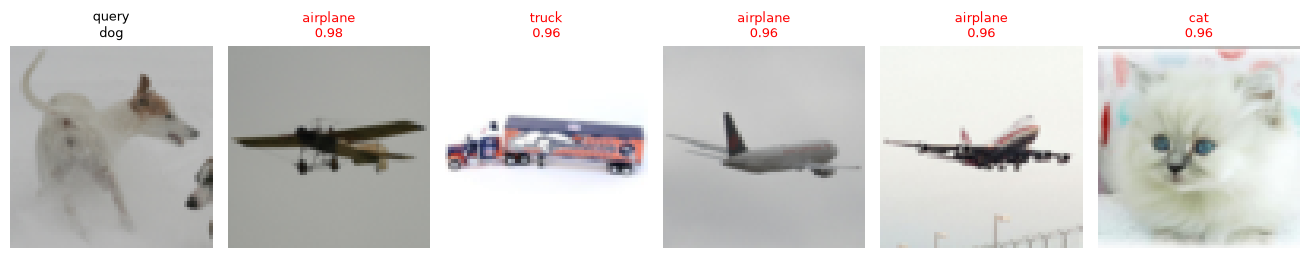

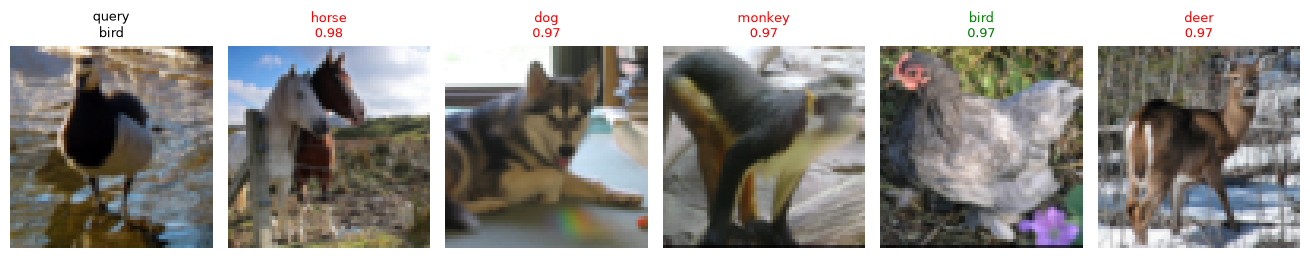

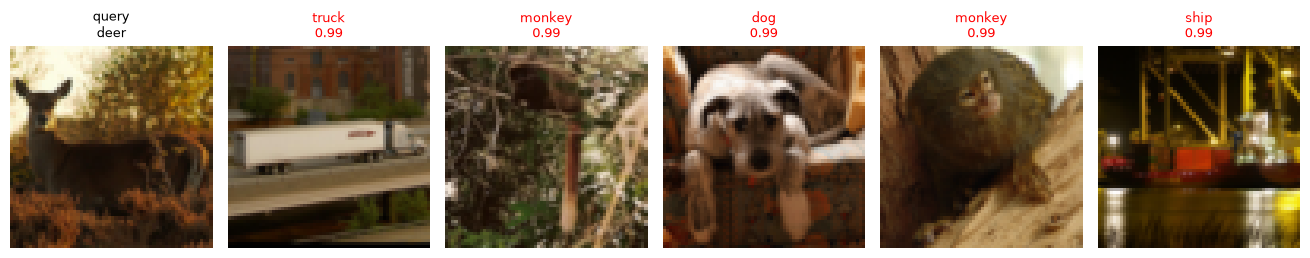

In [9]:
# Normalize features so dot product == cosine similarity.
feat_norm = torch.nn.functional.normalize(test_f, dim=1)

def show_neighbors(query_idx, k=5):
    sims = feat_norm @ feat_norm[query_idx]      # (N,)
    sims[query_idx] = -1                          # exclude the query itself
    top = sims.topk(k).indices

    fig, axes = plt.subplots(1, k + 1, figsize=(2.2 * (k + 1), 2.6))
    q_img, q_label = test_ds[query_idx]
    axes[0].imshow(unnormalize(q_img))
    axes[0].set_title(f"query\n{CLASSES[q_label]}", fontsize=9)
    axes[0].axis("off")
    for j, ni in enumerate(top):
        n_img, n_label = test_ds[ni.item()]
        same = (n_label == q_label)
        axes[j + 1].imshow(unnormalize(n_img))
        axes[j + 1].set_title(f"{CLASSES[n_label]}\n{sims[ni]:.2f}",
                              color=("green" if same else "red"), fontsize=9)
        axes[j + 1].axis("off")
    plt.tight_layout()
    plt.show()

# A few query images from different classes.
for q in [0, 1, 2, 5, 8]:
    show_neighbors(q, k=5)

In [10]:
# Bonus: k-NN classification accuracy (k=20) straight from the features,
# no training involved. A quick sanity check on feature quality.
K = 20
sim_matrix = feat_norm @ feat_norm.T
sim_matrix.fill_diagonal_(-1)
knn = sim_matrix.topk(K, dim=1).indices          # (N, K)
neigh_labels = test_y[knn]                        # (N, K)
# majority vote
knn_pred = torch.mode(neigh_labels, dim=1).values
knn_acc = (knn_pred == test_y).float().mean().item()
print(f"{K}-NN accuracy on test features: {knn_acc:.4f}")

20-NN accuracy on test features: 0.3206
